In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('../src')
    
from pathlib import Path
from matplotlib import pyplot as plt
from joblib import load
import polars as pl
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, StratifiedGroupKFold
from sklearn.metrics import f1_score, ConfusionMatrixDisplay

plato_data_directory = Path('/STER/mamsie/tess/TIC/plato_fov/')
training_set = "training_df_try8"
save_path = Path('../results/classifications') / training_set

with open(save_path / 'model.pkl', "rb") as f:
    clf_features = load(f)

with open(save_path / 'label_encoder.pkl', "rb") as f:
    le = load(f)

df_training_set = pl.read_parquet(plato_data_directory / f"{training_set}.parquet").select(['path', 'label', 'GaiaID'])#.rename({'FilePath': 'path'})
tic_train = pl.read_csv(plato_data_directory / f"{training_set}_train_gaiaids.csv").to_series().to_list()
tic_val = pl.read_csv(plato_data_directory / f"{training_set}_val_gaiaids.csv").to_series().to_list()
tic_test = pl.read_csv(plato_data_directory / f"{training_set}_test_gaiaids.csv").to_series().to_list()

# Average of neural net and feature based classifier

In [2]:
# Loading feature-based classifier probabilities

df_feature_classifier = pl.read_parquet(save_path / 'predictions.parquet').with_columns(
    pl.concat_arr([pl.col(name) for name in le.classes_]).alias('rf_probs')
)
df_feature_classifier.head(5)

path,APERIODIC,CONTACT_ROT,DSCT_BCEP,ECLIPSE,GDOR_SPB,INSTRUMENT/JUNK,RRLYR_CEPH,SOLARLIKE,best_rf_class,rf_entropy,best_rf_proba,rf_probs
str,f32,f32,f32,f32,f32,f32,f32,f32,str,f64,f32,"array[f32, 8]"
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000375,0.00664,0.000045,0.000081,0.008243,0.982678,0.000009,0.001928,"""INSTRUMENT/JUNK""",0.051144,0.982678,"[0.000375, 0.00664, … 0.001928]"
"""/STER/mamsie/tess/TIC/tglc_scr…",0.005536,0.000425,0.000061,0.000009,0.000744,0.000506,0.000004,0.992716,"""SOLARLIKE""",0.023691,0.992716,"[0.005536, 0.000425, … 0.992716]"
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000154,0.000771,0.998956,0.000004,0.000068,0.000016,0.000002,0.00003,"""DSCT_BCEP""",0.004392,0.998956,"[0.000154, 0.000771, … 0.00003]"
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000032,0.983183,0.000227,0.000155,0.012708,0.001946,0.000261,0.001487,"""CONTACT_ROT""",0.047965,0.983183,"[0.000032, 0.983183, … 0.001487]"
"""/STER/mamsie/tess/TIC/tglc_scr…",0.000148,0.001811,0.907923,0.001159,0.00379,0.083499,0.00002,0.001651,"""DSCT_BCEP""",0.167122,0.907923,"[0.000148, 0.001811, … 0.001651]"


In [3]:
# Loading nnet training set probabilities

labels = le.classes_.copy()
labels[5] = 'JUNK'
labels

df_nnet = pl.read_csv('~/predictions_training_set.csv').with_columns(
    nnet_probs = pl.col("probabilities").str.json_decode(dtype=pl.Struct([pl.Field(name, pl.Float64) for name in labels]))
).with_columns(
    pl.concat_arr(
        [pl.col("nnet_probs").struct.field(k).cast(pl.Float64) for k in labels]
    ).alias('nnet_probs')
).rename({'FilePath': 'path'})
df_nnet.head(5)

tic,path,label,GaiaID,sector,power,probabilities,nnet_probs
i64,str,str,i64,str,f64,str,"array[f64, 8]"
258352700,"""/STER/mamsie/tess/TIC/tglc_scr…","""CONTACT_ROT""",2249305129178207744,"""s0021""",0.265248,"""{""APERIODIC"": 2e-06, ""CONTACT_…","[0.000002, 0.896807, … 0.000689]"
399867067,"""/STER/mamsie/tess/TIC/tglc_scr…","""INSTRUMENT/JUNK""",2132866366763430912,"""s0040""",0.099279,"""{""APERIODIC"": 0.000326, ""CONTA…","[0.000326, 0.023655, … 0.060938]"
199418105,"""/STER/mamsie/tess/TIC/tglc_scr…","""SOLARLIKE""",1860931646295939712,"""s0041""",0.030439,"""{""APERIODIC"": 2.6e-05, ""CONTAC…","[0.000026, 0.001319, … 0.941119]"
219820925,"""/STER/mamsie/tess/TIC/tglc_scr…","""DSCT_BCEP""",1435190745326633984,"""s0026""",0.433152,"""{""APERIODIC"": 1e-06, ""CONTACT_…","[0.000001, 0.001116, … 0.00006]"
441721258,"""/STER/mamsie/tess/TIC/tglc_scr…","""GDOR_SPB""",1656523844747203840,"""s0021""",0.401333,"""{""APERIODIC"": 0.0, ""CONTACT_RO…","[0.0, 0.000302, … 0.000009]"


In [4]:
# Joining
df_meta_train = df_nnet.join(df_feature_classifier, on='path').select(['path', 'GaiaID', 'label', 'nnet_probs', 'rf_probs'])
df_meta_train.head(5)

path,GaiaID,label,nnet_probs,rf_probs
str,i64,str,"array[f64, 8]","array[f32, 8]"
"""/STER/mamsie/tess/TIC/tglc_scr…",2249305129178207744,"""CONTACT_ROT""","[0.000002, 0.896807, … 0.000689]","[0.000684, 0.95927, … 0.001686]"
"""/STER/mamsie/tess/TIC/tglc_scr…",2132866366763430912,"""INSTRUMENT/JUNK""","[0.000326, 0.023655, … 0.060938]","[0.000375, 0.00664, … 0.001928]"
"""/STER/mamsie/tess/TIC/tglc_scr…",1860931646295939712,"""SOLARLIKE""","[0.000026, 0.001319, … 0.941119]","[0.005536, 0.000425, … 0.992716]"
"""/STER/mamsie/tess/TIC/tglc_scr…",1435190745326633984,"""DSCT_BCEP""","[0.000001, 0.001116, … 0.00006]","[0.000154, 0.000771, … 0.00003]"
"""/STER/mamsie/tess/TIC/tglc_scr…",1656523844747203840,"""GDOR_SPB""","[0.0, 0.000302, … 0.000009]","[0.000001, 0.000079, … 0.000005]"


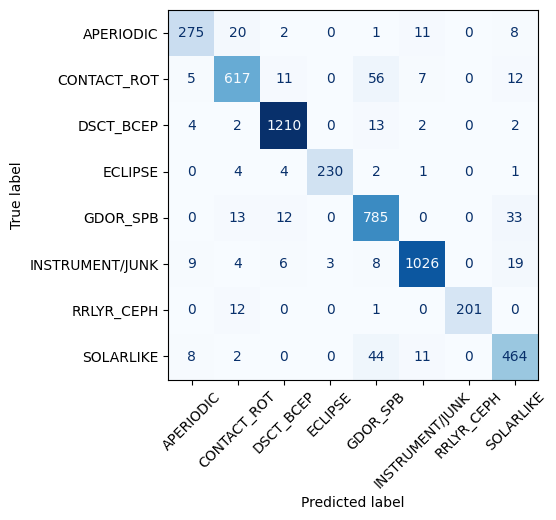

In [5]:
df_meta_test = df_meta_train.filter(pl.col('GaiaID').is_in(tic_test))
nnet_probs = df_meta_test['nnet_probs'].to_numpy()
rf_probs = df_meta_test['rf_probs'].to_numpy()
label_test = df_meta_test['label'].to_numpy()

average_probs = (nnet_probs + rf_probs)/2
average_y_test = average_probs.argmax(axis=-1)

ConfusionMatrixDisplay.from_predictions(y_pred=le.inverse_transform(average_y_test), y_true=label_test, cmap=plt.cm.Blues, xticks_rotation=45,colorbar=False)

# Stacking classifier

- Stacking classifier takes the concantenation of neural net and feature-based classifier probabilities as input
- We use a linear model for interpretability but also because it is less capable of overfitting
- The stacking classifier is trained in the validation set to reduce leakage
- The feature based classifier was trained using cross validation and refitted into the whole train+validation partition. Here we retraining using the training partition only

In [6]:
from training import prepare_features_for_classification

def to_numpy_arrays(df):
    path = df['path'].to_numpy()
    y = df['label'].to_numpy()
    X = df.drop(['GaiaID', 'path', 'label']).to_numpy()
    return X[:, selected_features], y, path

feature_config = load(save_path / 'feature_config.pkl')
selected_features = load(save_path / 'selected_features.pkl')
preprocessor = load(save_path / 'preprocessor.pkl')

df_training_features = pl.read_parquet(f'../results/features/{training_set}').join(df_training_set, on='path')
df_training_features, _ = prepare_features_for_classification(df_training_features, **feature_config)
X_train, y_train, path_train = to_numpy_arrays(df_training_features.filter(pl.col('GaiaID').is_in(tic_train)))
X_val, y_val, path_val = to_numpy_arrays(df_training_features.filter(pl.col('GaiaID').is_in(tic_val)))
X_test, y_test, path_test = to_numpy_arrays(df_training_features.filter(pl.col('GaiaID').is_in(tic_test)))

clf_features.fit(preprocessor.transform(X_train), le.transform(y_train))
rf_probs = clf_features.predict_proba(preprocessor.transform(np.concatenate([X_val, X_test], axis=0)))
df_rf_oob = pl.DataFrame({'path': np.concatenate([path_val, path_test]), 'rf_probs': rf_probs})

In [7]:
# Joining
df_meta_train = df_nnet.join(df_rf_oob, on='path').select(['path', 'GaiaID', 'label', 'nnet_probs', 'rf_probs'])
df_meta_train.head(5)

path,GaiaID,label,nnet_probs,rf_probs
str,i64,str,"array[f64, 8]","array[f32, 8]"
"""/STER/mamsie/tess/TIC/tglc_scr…",2249305129178207744,"""CONTACT_ROT""","[0.000002, 0.896807, … 0.000689]","[0.001779, 0.882627, … 0.002845]"
"""/STER/mamsie/tess/TIC/tglc_scr…",1656523844747203840,"""GDOR_SPB""","[0.0, 0.000302, … 0.000009]","[0.000002, 0.000103, … 0.000008]"
"""/STER/mamsie/tess/TIC/tglc_scr…",2245138529867293184,"""DSCT_BCEP""","[0.0, 0.000114, … 0.0]","[0.000001, 0.000028, … 0.000027]"
"""/STER/mamsie/tess/TIC/tglc_scr…",2086452957301741952,"""INSTRUMENT/JUNK""","[0.001105, 0.015077, … 0.12477]","[0.000388, 0.005059, … 0.004672]"
"""/STER/mamsie/tess/TIC/tglc_scr…",2259368409350886144,"""INSTRUMENT/JUNK""","[0.000006, 0.000206, … 0.006533]","[0.000306, 0.000067, … 0.003295]"


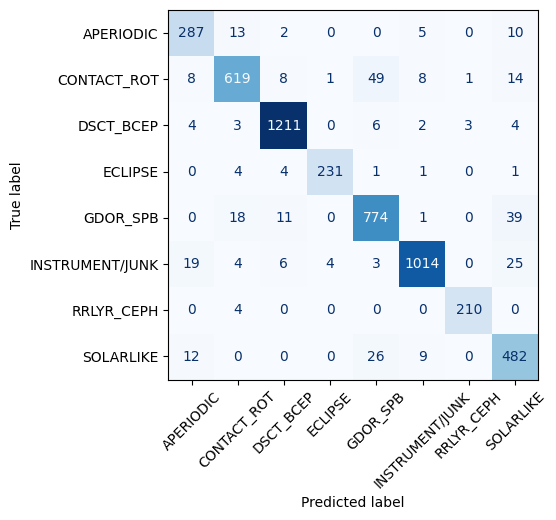

In [8]:
# Fitting the stacking classifier
df_meta_fit = df_meta_train.filter(pl.col('GaiaID').is_in(tic_val))
nnet_probs = df_meta_fit['nnet_probs'].to_numpy()
rf_probs = df_meta_fit['rf_probs'].to_numpy()

meta_clf = LogisticRegression(fit_intercept=False, C=0.5, l1_ratio=1.0, solver='saga', max_iter=1000, class_weight='balanced')
meta_clf.fit(np.concatenate([nnet_probs, rf_probs], axis=1), df_meta_fit['label'].to_numpy())

df_meta_test = df_meta_train.filter(pl.col('GaiaID').is_in(tic_test))
nnet_probs = df_meta_test['nnet_probs'].to_numpy()
rf_probs = df_meta_test['rf_probs'].to_numpy()
probs = np.concatenate([nnet_probs, rf_probs], axis=1)
label_test = df_meta_test['label'].to_numpy()
meta_y_test_proba = meta_clf.predict_proba(probs)
meta_y_test = meta_clf.predict(probs)

ConfusionMatrixDisplay.from_predictions(y_pred=meta_y_test, y_true=label_test, cmap=plt.cm.Blues, xticks_rotation=45,colorbar=False)

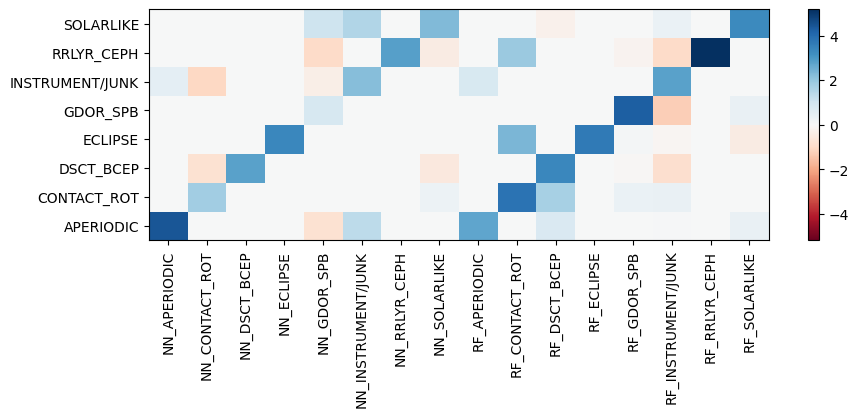

In [9]:
# Visualazing the linear regression coefficients
fig, ax = plt.subplots(figsize=(10, 3))
im = plt.pcolormesh(range(16), meta_clf.classes_, meta_clf.coef_, cmap=plt.cm.RdBu, vmin=-np.amax(np.abs(meta_clf.coef_)), vmax=np.amax(np.abs(meta_clf.coef_)))
plt.colorbar(im)
ax.set_xticks(range(16))
ax.set_xticklabels(['NN_'+name for name in meta_clf.classes_] + ['RF_'+name for name in meta_clf.classes_]);
ax.tick_params(axis='x', labelrotation=90)

In [10]:
for name, str_nnet, str_rf in zip(meta_clf.classes_, np.sqrt(np.sum(meta_clf.coef_[:, :8]**2, axis=1)), np.sqrt(np.sum(meta_clf.coef_[:, 8:]**2, axis=1))):
    print(f"{name:15}: {str_nnet:6f}\t {str_rf:6f}")

APERIODIC      : 4.683207	 2.858846
CONTACT_ROT    : 1.819334	 4.229727
DSCT_BCEP      : 2.966009	 3.510121
ECLIPSE        : 3.375456	 4.385780
GDOR_SPB       : 0.852824	 4.492648
INSTRUMENT/JUNK: 2.524366	 2.930295
RRLYR_CEPH     : 3.063890	 5.613018
SOLARLIKE      : 2.958612	 3.314726


Neural net contributes more towards APERIODIC classification. They are closer for SOLARLIKE and INSTRUMENT. Feature-based classifier is stronger on the rest, specially so for CONTACT_ROT, GDOR and RRLYR